In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
#Set a random seed for reproducibility
np.random.seed(42)

In [4]:
#Generate a simple linear dataset
n_samples = 30
X_input = np.linspace(0, 10, n_samples)
y = 2 * X_input + 1 + np.random.randn(n_samples) # True slope = 2, intercept = 1, some noise

In [5]:
#Add three inpactful outliers
X_input = np.append(X_input, [15, 18, 20]) #Farther on the x-axis
y = np.append(y, [80, 90, 100]) #Much higher y-values

In [6]:
#Add the intercept term
X = np.hstack([np.ones((n_samples + 3, 1)), X_input.reshape(-1, 1)])

In [9]:
#Compute the OLS and Ridge regression solutions
beta_OLS = np.linalg.inv(X.T @ X) @ X.T @ y
lambda_ridge = 1000 #A stronger lambda to emphasize Ridge's dampening effect
I = np.eye(X.shape[1])
beta_Ridge = np.linalg.inv(X.T @ X + lambda_ridge * I) @ X.T @ y

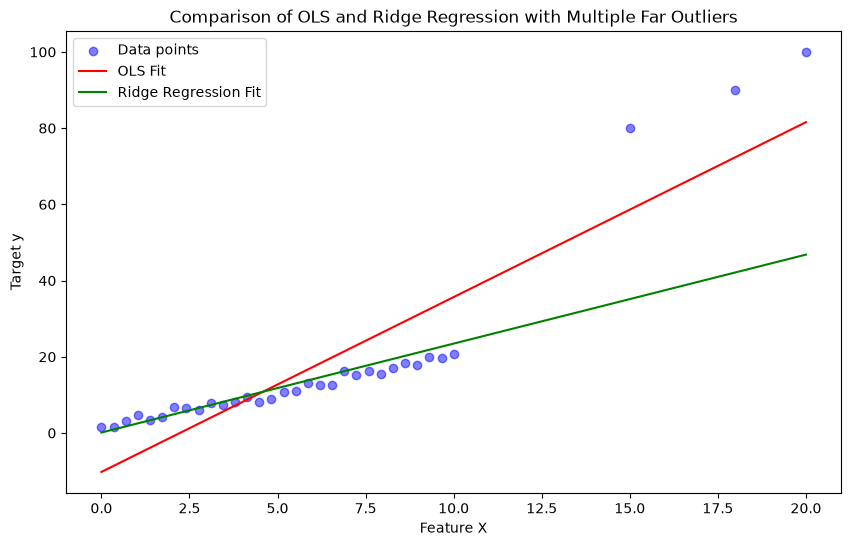

In [15]:
#Prepare to plot
plt.figure(figsize=[10, 6])
plt.scatter(X_input, y, color='blue', alpha=0.5, label='Data points')

#Plot the OLS fit
x_range = np.linspace(np.min(X_input), np.max(X_input), 100)
y_OLS = beta_OLS[0] + beta_OLS[1] * x_range
plt.plot(x_range, y_OLS, 'r-', label='OLS Fit')

#Plot the Ridge regression fit
y_Ridge = beta_Ridge[0] + beta_Ridge[1] * x_range
plt.plot(x_range, y_Ridge, 'g-', label='Ridge Regression Fit')

plt.xlabel('Feature X')
plt.ylabel('Target y')
plt.title('Comparison of OLS and Ridge Regression with Multiple Far Outliers')
plt.legend()
plt.show()